## Meshing from a DEM: Merewether

A uniform mesh spends its triangles evenly, but water does not go everywhere evenly. In a town it runs down the streets and the overland flow paths between houses, and the ground in between matters much less. Those paths are written in the elevation model.

`anuga.create_domain_from_dem` reads them from the DEM. It routes the DEM by D8 (each cell drains to its steepest downhill neighbour), which gives every cell the area draining through it, and makes the mesh fine where a lot drains through and coarse elsewhere. The resolution comes from a graded *size field*, so no extra segments enter the mesh, and the worst cells are relaxed afterwards.

Here we use it on the Merewether case (a 2007 flood in Newcastle, NSW; see `validation_tests/case_studies/merewether`) and compare it with a uniform 1 m² mesh: triangle count, timestep, run time, and the flood levels at the five points where the flood was observed.

In [1]:
import glob
import os
import pathlib
import time

import numpy as np
import matplotlib.pyplot as plt

import anuga
from anuga.pmesh.dem_mesh import read_dem, elevation_from_dem

%matplotlib inline

# Allow inline jshtml animations
from matplotlib import rc
rc('animation', html='jshtml')

# Root of the anuga_core repository (works for editable installs and Codespaces)
ANUGA_CORE = str(pathlib.Path(anuga.__file__).parent.parent)
data_dir = os.path.join(ANUGA_CORE, 'examples', 'data', 'merewether')
print(f"Data directory: {data_dir}")

Data directory: /home/steve/anuga_core/examples/data/merewether


### The data

A 1 m DEM, the outline of the model, and 58 houses as polygons.

DEM: 321 x 416 cells of 1.00 m, elevation 16.5 to 52.0 m
58 houses


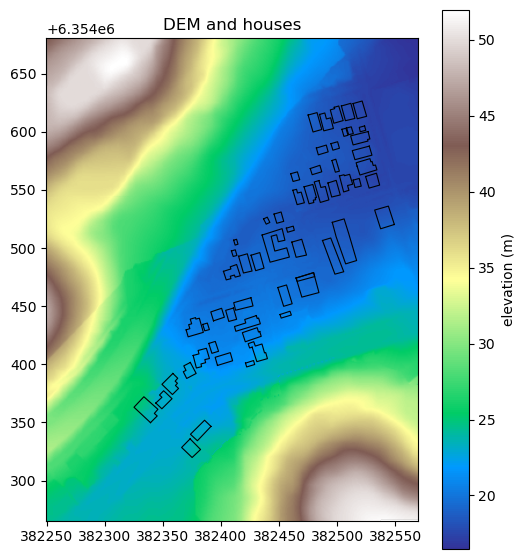

In [2]:
dem_file = os.path.join(data_dir, 'topography1.asc')
bounding_polygon = anuga.read_polygon(os.path.join(data_dir, 'extent.csv'))
boundary_tags = {'bottom': [0], 'right': [1], 'top': [2], 'left': [3]}

house_files = sorted(glob.glob(os.path.join(data_dir, 'house*.csv')))
houses = [anuga.read_polygon(f) for f in house_files]

x, y, Z = read_dem(dem_file)
print(f"DEM: {len(x)} x {len(y)} cells of {x[1] - x[0]:.2f} m, "
      f"elevation {np.nanmin(Z):.1f} to {np.nanmax(Z):.1f} m")
print(f"{len(houses)} houses")

def draw_houses(ax, polygons, **kw):
    for h in polygons:
        h = np.array(h + [h[0]])
        ax.plot(h[:, 0], h[:, 1], **kw)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(Z.T, origin='lower', cmap='terrain',
               extent=[x[0], x[-1], y[0], y[-1]])
draw_houses(ax, houses, color='k', lw=0.8)
ax.set_aspect('equal')
plt.colorbar(im, ax=ax, label='elevation (m)')
ax.set_title('DEM and houses');

### Tidying the houses

Every hole goes into the mesh exactly, corners and all, and triangles cannot be much smaller than the shortest side or the narrowest gap they sit against. Since ANUGA steps at its smallest triangle, one fussy house outline can set the timestep of the whole run. Two things in this data do that:

- short sides: the shortest is under 1 m;
- houses that overlap or almost touch: `house030` overlaps `house029`, sharing a corner and part of a side with it, and `house052` and `house054` are 0.6 m apart. The validation case leaves `house030` out for this reason.

A gap narrower than a metre carries no useful flow at this scale, so we merge houses closer than 1 m (with `shapely`, by growing each house by half a metre, taking the union and shrinking it back). Then we drop vertices until no side is shorter than 2 m, each time removing the one that changes the outline least.

ANUGA does not do this for you: whether a gap or a short side matters is a modelling decision. A house corner that steers the flow round it should stay.

58 houses -> 56; shortest side 0.94 m -> 2.08 m; area 6,044 -> 6,003 m2


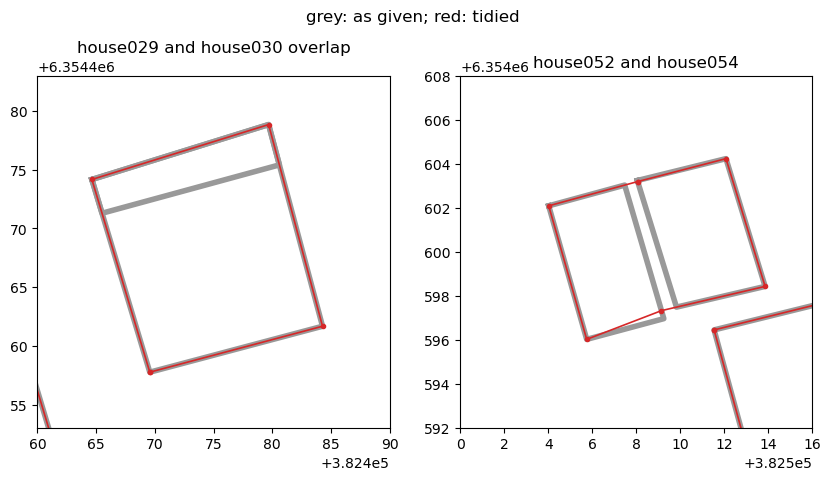

In [3]:
from shapely.geometry import Polygon
from shapely.ops import unary_union


def drop_short_sides(poly, min_side):
    # Remove vertices until no side is shorter than min_side, each time
    # removing whichever end of the shortest side changes the area least
    p = [tuple(v) for v in poly]
    while len(p) > 4:
        P = np.array(p)
        side = np.hypot(*(np.roll(P, -1, axis=0) - P).T)
        k = int(side.argmin())
        if side[k] >= min_side:
            break
        def change(i):
            a, b, c = P[i - 1], P[i], P[(i + 1) % len(P)]
            return abs((b[0] - a[0]) * (c[1] - a[1]) - (c[0] - a[0]) * (b[1] - a[1]))
        p.pop(k if change(k) <= change((k + 1) % len(P)) else (k + 1) % len(P))
    return [list(v) for v in p]


def clean_houses(polygons, gap=1.0, min_side=2.0):
    merged = unary_union([Polygon(h).buffer(gap / 2, join_style='mitre')
                          for h in polygons]).buffer(-gap / 2, join_style='mitre')
    out = []
    for g in getattr(merged, 'geoms', [merged]):
        g = g.simplify(0.05)            # drop points left in a straight side
        ring = list(g.exterior.coords)[:-1]
        if not g.exterior.is_ccw:
            ring = ring[::-1]
        out.append(drop_short_sides(ring, min_side))
    return out


def shortest_side(polygons):
    return min(np.hypot(*np.diff(np.vstack([h, h[:1]]), axis=0).T).min()
               for h in map(np.array, polygons))


clean = clean_houses(houses)
print(f"{len(houses)} houses -> {len(clean)}; shortest side "
      f"{shortest_side(houses):.2f} m -> {shortest_side(clean):.2f} m; area "
      f"{sum(Polygon(h).area for h in houses):,.0f} -> "
      f"{sum(Polygon(h).area for h in clean):,.0f} m2")

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
for ax, (x0, y0, w), title in zip(axs, [(382460, 6354453, 30), (382500, 6354592, 16)],
                                  ['house029 and house030 overlap', 'house052 and house054']):
    draw_houses(ax, houses, color='0.6', lw=4)
    draw_houses(ax, clean, color='C3', lw=1.2, marker='.')
    ax.set_xlim(x0, x0 + w); ax.set_ylim(y0, y0 + w); ax.set_aspect('equal')
    ax.set_title(title)
fig.suptitle('grey: as given; red: tidied');

### Where the water goes

`anuga.drainage_area_from_dem` shows the routing that the mesh will be sized from. Depressions are filled first, so that every cell drains; water leaves across the bounding polygon and flows around the houses.

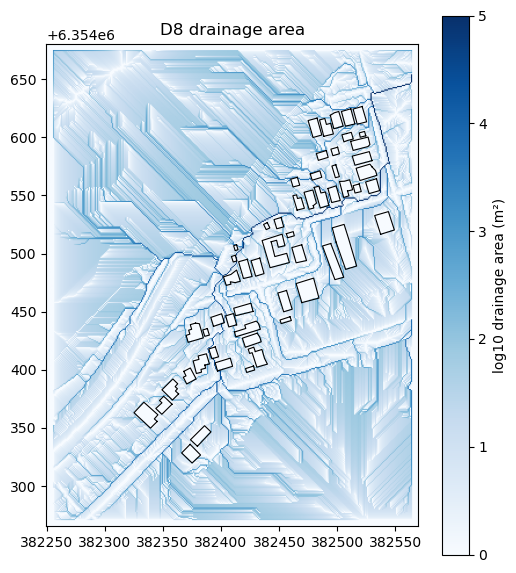

In [4]:
X, Y, A = anuga.drainage_area_from_dem(dem_file, bounding_polygon=bounding_polygon,
                                       interior_holes=clean)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(np.log10(np.maximum(A, 1.0)).T, origin='lower', cmap='Blues',
               extent=[X[0], X[-1], Y[0], Y[-1]], vmin=0, vmax=5)
draw_houses(ax, clean, color='k', lw=0.8)
ax.set_aspect('equal')
plt.colorbar(im, ax=ax, label='log10 drainage area (m²)')
ax.set_title('D8 drainage area');

### The meshes

**Uniform.** The validation case's mesh: triangles of at most 1 m² over the town (`merewether.csv`) and 2 m² elsewhere, with the houses as given (less `house030`).

**From the DEM.** Triangles of at most 2 m² where 5000 m² or more drains through, 4 m² where 1000 m² does, and 8 m² elsewhere, with the tidied houses. `create_domain_from_dem` also relaxes the worst cells (`relax_passes=30` by default).

Each triangle's elevation is the mean of the DEM over it, the same way for both. `create_domain_from_dem` does this itself. For a domain made any other way, `elevation_from_dem` gives the same values; or use ANUGA's general route, which interpolates the DEM at the centroids:

```python
domain.set_quantity('elevation', filename=dem_file, location='centroids')
```

In [5]:
def mesh_stats(name, domain):
    r = domain.radii
    print(f"{name:9s} {len(domain):8,d} triangles, smallest radius {r.min():.3f} m, "
          f"median {np.median(r):.3f} m")

town = anuga.read_polygon(os.path.join(data_dir, 'merewether.csv'))
uniform = anuga.create_domain_from_regions(
    bounding_polygon, boundary_tags, maximum_triangle_area=2.0,
    interior_regions=[[town, 1.0]],
    interior_holes=[h for h, f in zip(houses, house_files) if 'house030' not in f],
    verbose=False)
uniform.set_quantity('elevation', elevation_from_dem(uniform, dem_file),
                     location='centroids')

from_dem = anuga.create_domain_from_dem(
    dem_file, maximum_triangle_area=8.0,
    bounding_polygon=bounding_polygon, boundary_tags=boundary_tags,
    streams=[(5000.0, 2.0), (1000.0, 4.0)],
    interior_holes=clean)

mesh_stats('uniform', uniform)
mesh_stats('from DEM', from_dem)

uniform    122,953 triangles, smallest radius 0.135 m, median 0.358 m
from DEM    31,095 triangles, smallest radius 0.366 m, median 0.731 m


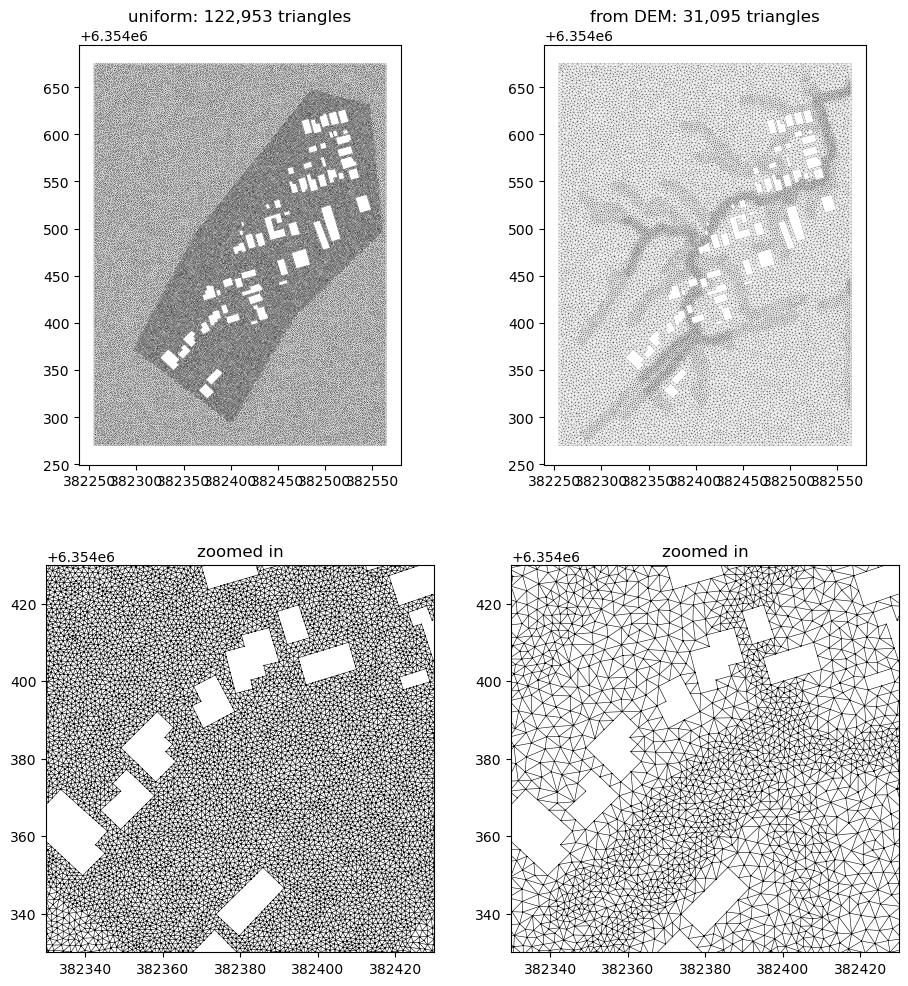

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(11, 12))
for col, (name, domain) in enumerate([('uniform', uniform), ('from DEM', from_dem)]):
    nodes = domain.get_nodes(absolute=True)
    for row, lw in enumerate([0.1, 0.4]):
        ax = axs[row, col]
        ax.triplot(nodes[:, 0], nodes[:, 1], domain.get_triangles(), lw=lw, color='k')
        ax.set_aspect('equal')
    axs[0, col].set_title(f'{name}: {len(domain):,} triangles')
    axs[1, col].set_xlim(382330, 382430); axs[1, col].set_ylim(6354330, 6354430)
    axs[1, col].set_title('zoomed in')

### The flood

As in the validation case: 19.7 m³/s comes in at the south-west corner, the north and east sides let water out, and Manning's n is 0.02 on the roads and 0.04 elsewhere. We run each mesh for 1000 s, by when the flow is steady.

In [7]:
from anuga.utilities import quantity_setting_functions as qs

road = anuga.read_polygon(os.path.join(data_dir, 'RoadPolygon.csv'))


def run(domain, name, animate=False):
    domain.set_name(name)
    domain.set_quantity('friction', qs.composite_quantity_setting_function(
        [[road, 0.02], ['All', 0.04]], domain))
    domain.set_quantity('stage', expression='elevation')
    Br = anuga.Reflective_boundary(domain)
    Bt = anuga.Transmissive_boundary(domain)
    domain.set_boundary({'bottom': Br, 'right': Bt, 'top': Bt, 'left': Br,
                         'interior': Br})
    inflow = anuga.Region(domain, center=(382265.0, 6354280.0), radius=10.0)
    anuga.Inlet_operator(domain, inflow, Q=19.7)

    if animate:
        domain.set_plotter(absolute=True)     # adds save_depth_frame etc.
    steps, plotting, t0 = 0, 0.0, time.time()
    for t in domain.evolve(yieldstep=10, finaltime=1000):
        if t > 0:
            steps += domain.number_of_steps
        if animate and t % 50 == 0:
            t1 = time.time()
            domain.save_depth_frame(vmin=0.0, vmax=1.0, dpi=60, figsize=(6, 7))
            plotting += time.time() - t1
    wall = time.time() - t0 - plotting        # the run alone
    print(f"{name:20s} {steps:7,d} steps, mean timestep {1000 / steps:.4f} s, "
          f"{wall:6.1f} s")
    return wall


wall = {'uniform': run(uniform, 'merewether_uniform'),
        'from DEM': run(from_dem, 'merewether_from_dem', animate=True)}
print(f"The DEM mesh ran {wall['uniform'] / wall['from DEM']:.1f} times faster")

merewether_uniform    30,734 steps, mean timestep 0.0325 s,   94.6 s


merewether_from_dem   14,435 steps, mean timestep 0.0693 s,    8.6 s
The DEM mesh ran 10.9 times faster


While the DEM mesh ran, `save_depth_frame` saved a picture of the depth every 50 s (only on the faster run, to keep the notebook quick). `make_depth_animation` plays them back.

In [8]:
from_dem.make_depth_animation()

### Against the observations

The observed flood levels at five points, from the Australian Rainfall and Runoff report, with TUFLOW's results from the same report. For each point we take the nearest wet triangle at the end of the run.

In [9]:
obs = np.genfromtxt(os.path.join(data_dir, 'ObservationPoints.csv'),
                    delimiter=',', skip_header=1)

def stage_at(sww, points):
    out = anuga.SWW_plotter(sww)
    xc, yc = out.xc + out.xllcorner, out.yc + out.yllcorner
    wet = out.depth[-1] > 1.0e-3
    i = [np.argmin((xc - px)**2 + (yc - py)**2 + 1.0e6 * ~wet) for px, py in points]
    return out.stage[-1, i]

s_uniform = stage_at('merewether_uniform.sww', obs[:, :2])
s_dem = stage_at('merewether_from_dem.sww', obs[:, :2])

print(' ID   observed  TUFLOW  uniform  from DEM')
for row, su, sd in zip(obs, s_uniform, s_dem):
    print(f"{int(row[2]):3d} {row[4]:9.2f} {row[5]:7.2f} {su:8.2f} {sd:9.2f}")
for name, s in [('TUFLOW', obs[:, 5]), ('uniform', s_uniform), ('from DEM', s_dem)]:
    print(f"RMS difference from observed, {name}: "
          f"{np.sqrt(np.mean((s - obs[:, 4])**2)):.2f} m")

 ID   observed  TUFLOW  uniform  from DEM
  4     23.01   22.77    22.78     22.79
  3     23.14   23.11    23.06     23.07
  0     19.98   20.08    20.11     20.13
  1     18.38   18.36    18.41     18.41
  2     23.36   23.56    23.50     23.51
RMS difference from observed, TUFLOW: 0.15 m
RMS difference from observed, uniform: 0.14 m
RMS difference from observed, from DEM: 0.14 m


### Everywhere else

The observation points are only five. The map below shows the difference in peak depth between the two runs on a 1 m grid, taking each grid point's value from the nearest triangle, wherever either run was wet.

Peak depth, DEM mesh minus uniform, where wet: median +0.015 m, mean absolute 0.037 m, 95% within 0.103 m


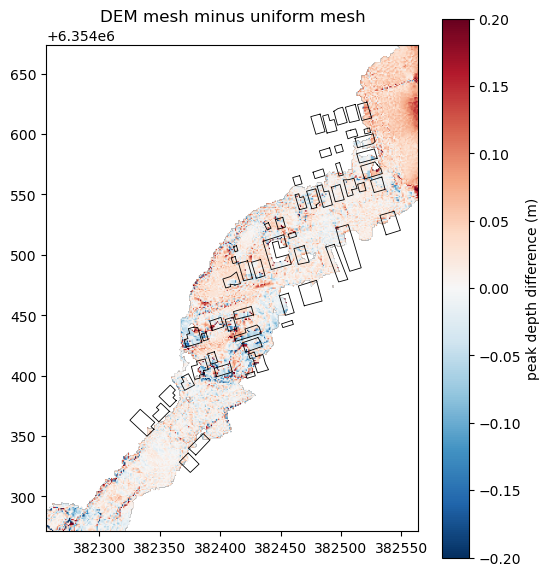

In [10]:
from scipy.spatial import cKDTree

gx, gy = np.meshgrid(np.arange(382256.0, 382565.0), np.arange(6354271.0, 6354675.0))
pts = np.column_stack([gx.ravel(), gy.ravel()])

def peak_depth(sww):
    out = anuga.SWW_plotter(sww)
    tree = cKDTree(np.column_stack([out.xc + out.xllcorner, out.yc + out.yllcorner]))
    return out.depth.max(axis=0)[tree.query(pts)[1]].reshape(gx.shape)

d_uniform = peak_depth('merewether_uniform.sww')
d_dem = peak_depth('merewether_from_dem.sww')
wet = (d_uniform > 0.05) | (d_dem > 0.05)
diff = np.where(wet, d_dem - d_uniform, np.nan)
print(f"Peak depth, DEM mesh minus uniform, where wet: median {np.nanmedian(diff):+.3f} m, "
      f"mean absolute {np.nanmean(np.abs(diff)):.3f} m, "
      f"95% within {np.nanpercentile(np.abs(diff), 95):.3f} m")

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(diff, origin='lower', cmap='RdBu_r', vmin=-0.2, vmax=0.2,
               extent=[gx.min(), gx.max(), gy.min(), gy.max()])
draw_houses(ax, clean, color='k', lw=0.6)
ax.set_aspect('equal')
plt.colorbar(im, ax=ax, label='peak depth difference (m)')
ax.set_title('DEM mesh minus uniform mesh');

### Summary

With a quarter of the triangles, a timestep twice as long and a run several times faster, the DEM-sized mesh gives the same flood levels at the observation points as the uniform mesh, to a couple of centimetres, and agrees with the observations as well. Over the rest of the flood the peak depths mostly differ by a few centimetres; the larger differences are beside houses whose outlines we tidied, and along the north-east edge where the water leaves.

Things to adjust for your own model:

- `streams`: the drainage areas that count as a flow path, and the triangle size along each. Look at `anuga.drainage_area_from_dem` first; in a catchment the thresholds are in km², in a town in hundreds or thousands of m².
- `floodplain`: refines the ground a stream spreads over when it rises, by height above the stream (HAND), for river valleys.
- `regions`: polygons to refine for what the DEM cannot show, a structure or a town centre, without adding their outlines to the mesh.
- `pits` (with `pit_outlets`): on a coarse catchment mesh, averaging the DEM can leave cells lower than all their neighbours, which hold rain for good. `pits='fill'` or `'breach'` removes them; see `anuga.remove_mesh_pits`. Here the mesh is fine enough to resolve the streets, so we leave the elevation as sampled.

See *Creating a Domain* in the user guide for the details.